# **DSK807 Applied Machine Learning**
## **EX06: Designing and Training Neural Networks**

**Dataset:** Fashion-MNIST  
**Goal:** Learn how network structure and training settings affect classification performance.

In this exercise, you will train neural networks, change one setting at a time, and explain what happens.

**Important:** Use the validation accuracy to compare your experiments. Keep the test set for the final model only.

## **Prepare the dataset**

**Fashion-MNIST** contains grayscale images of clothing in 10 categories. Each image has 28 x 28 pixels. We will turn each image into 784 input values, just as we did with MNIST digits in L11.

| Label | Description |
| ----- | ----------- |
| 0     | T-shirt/top |
| 1     | Trouser     |
| 2     | Pullover    |
| 3     | Dress       |
| 4     | Coat        |
| 5     | Sandal      |
| 6     | Shirt       |
| 7     | Sneaker     |
| 8     | Bag         |
| 9     | Ankle boot  |

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


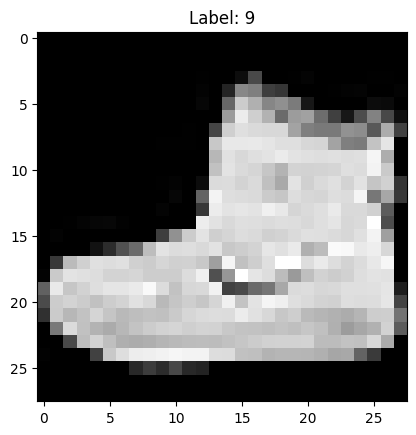

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load Fashion-MNIST
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

# Display one image
plt.imshow(X_train[0], cmap="gray")
plt.title("Label: " + str(y_train[0]))
plt.show()

In [ ]:
# Normalize pixel values to the range 0 to 1
X_train = X_train / 255.0
X_test = X_test / 255.0

# Convert 28 x 28 images into vectors of 784 values
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# Use a smaller training subset so experiments finish faster
# The last 5000 images will be used for validation
X_val = X_train[15000:20000]
y_val = y_train[15000:20000]
X_train_small = X_train[:15000]
y_train_small = y_train[:15000]

print("Training:", X_train_small.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (15000, 784)
Validation: (5000, 784)
Test: (10000, 784)


**Questions**
1. Why do we divide pixel values by 255?
2. Why does the input layer need 784 values?

**Note:** We use a smaller subset to save time in class. Results may change when training on the full dataset.


---

##**Train a baseline model**

Start with two hidden layers. We will use this model as a reference for the next tasks.

**Architecture:** 784 inputs, 64 neurons, 32 neurons, 10 outputs.

In [ ]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(784,)))
model.add(tf.keras.layers.Dense(64, activation="relu"))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(10, activation="softmax"))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train_small, y_train_small,
    epochs=8,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

In [ ]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

**Write down your baseline:** Training accuracy: ______  Validation accuracy: ______

**Questions:** Does training accuracy always increase? Is validation accuracy exactly the same as training accuracy?



---


## **Task 1: Change the number of hidden layers**

Create three models with the following hidden layers:

- **Model A:** 64
- **Model B:** 64, 32 (baseline)
- **Model C:** 64, 32, 16

**Your work:** Copy the baseline training cell into the empty cell below. Change only the `Dense` hidden-layer lines. Train each model for 8 epochs with batch size 64 and learning rate 0.001. Write down validation accuracy for each model.

**Tip:** To add a hidden layer, add another `model.add(tf.keras.layers.Dense(...))` line before the output layer.

In [ ]:
# Task 1: Paste the baseline model code here.
# First, train Model A with one hidden layer.
# Then change the hidden layers and train Model C.



| Model | Hidden layers | Validation accuracy |
|---|---|---|
| A | 64 | |
| B | 64, 32 | |
| C | 64, 32, 16 | |

**Questions:** Which model performs best? Does adding more layers always improve validation accuracy?



---


## **Task 2: Change the number of neurons**

Keep **one hidden layer** and compare 16, 64, and 256 neurons. Use the same learning rate, batch size, and number of epochs as before.

**Your work:** Copy the model code from Task 1 and change only the number of neurons. Train the three models.

In [ ]:
# Task 2: Paste your one-hidden-layer model here.
# Run it with 16, then 64, then 256 neurons.



| Neurons | Validation accuracy |
|---|---|
| 16 | |
| 64 | |
| 256 | |

**Questions:** What changes when you increase the number of neurons? Does the largest model always give the best result?



---


## **Task 3: Compare network structures**

Compare two models with three hidden layers:

- **Pyramid:** 128, 64, 32
- **Constant width:** 64, 64, 64

Keep the same optimizer, learning rate, batch size, and epochs.

**Your work:** Train both models. Use `model.summary()` to compare their number of parameters.

In [ ]:
# Task 3: Paste the baseline model code here.
# Add three hidden layers for the pyramid model.
# Then try the constant-width model.
# After creating each model, run:
# model.summary()



| Architecture | Number of parameters | Validation accuracy |
|---|---|---|
| 128, 64, 32 | | |
| 64, 64, 64 | | |

**Questions:** Which model has more parameters? Which model performs better? Can we conclude that one architecture is always better?



---


## **Task 4: Change the learning rate**

Return to the baseline architecture: 64, 32. Try these learning rates with Adam:

- 0.0001
- 0.001
- 0.1

**Your work:** Copy the baseline code and change only the value in `Adam(learning_rate=...)`. Compare the accuracy curves. If a model performs poorly, inspect its loss values.

In [ ]:
# Task 4: Paste the baseline code here.
# Change Adam(learning_rate=0.001) to the other values.



| Learning rate | Validation accuracy | Observation |
|---|---|---|
| 0.0001 | | |
| 0.001 | | |
| 0.1 | | |

**Questions:** Which learning rate works best after 8 epochs? What happens when the learning rate is too small or too large?



---


## **Task 5: Change batch size and epochs**

Use the baseline architecture and learning rate 0.001.

**Part A:** Compare `batch_size=16` and `batch_size=256`, with 8 epochs.

**Part B:** Keep `batch_size=64`, then train for 20 epochs. Plot training and validation accuracy.

**Your work:** Copy the baseline code and change only the indicated `model.fit()` settings. Recreate a fresh model before each run.

In [ ]:
# Task 5: Paste the baseline code here.
# Change batch_size and epochs as instructed.



| Experiment | Validation accuracy | Observation |
|---|---|---|
| Batch size 16, 8 epochs | | |
| Batch size 256, 8 epochs | | |
| Batch size 64, 20 epochs | | |

**Questions:** How does batch size change the number of updates per epoch? Does more training always improve validation accuracy?



---


## **Final challenge: Choose your best model**

You now have several results. Select the architecture and training settings that gave you the strongest validation performance.

1. Create a new model with your chosen number of hidden layers and neurons.
2. Select your learning rate, batch size, and epochs.
3. Train it using the same training subset and validation set.
4. Evaluate it on the **test set for the first time**.
5. Compare the test accuracy with your baseline validation accuracy, noting that they are measured on different data splits.

Do not change your model after seeing the test result. The test set is for final evaluation.

In [ ]:
# Final challenge: Build and train your selected model here.
# Use the baseline code as a starting point.



In [ ]:
# Run this cell after training your final model.
# The variable "model" must contain your final trained model.

test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Final test accuracy:", test_accuracy)



---


### **Final reflection**

1. Which architecture worked best in your experiments?
2. Which learning rate worked best?
3. What did you learn about batch size and epochs?
4. What is your final test accuracy?
5. Why is it important to change one parameter at a time?

**Reminder:** Small differences between runs can happen because neural network training includes randomness. A single experiment does not prove that one setting is always best.